           label  count
0   ddos_udp_lag   5986
1      ddos_snmp   5984
2      ddos_ssdp   5970
3      ddos_ldap   5928
4     ddos_mssql   5911
5       ddos_udp   5876
6   ddos_netbios   5830
7         benign   5658
8       ddos_syn   5480
9       ddos_dns   5369
10     ddos_tftp   5261
11      ddos_ntp    986


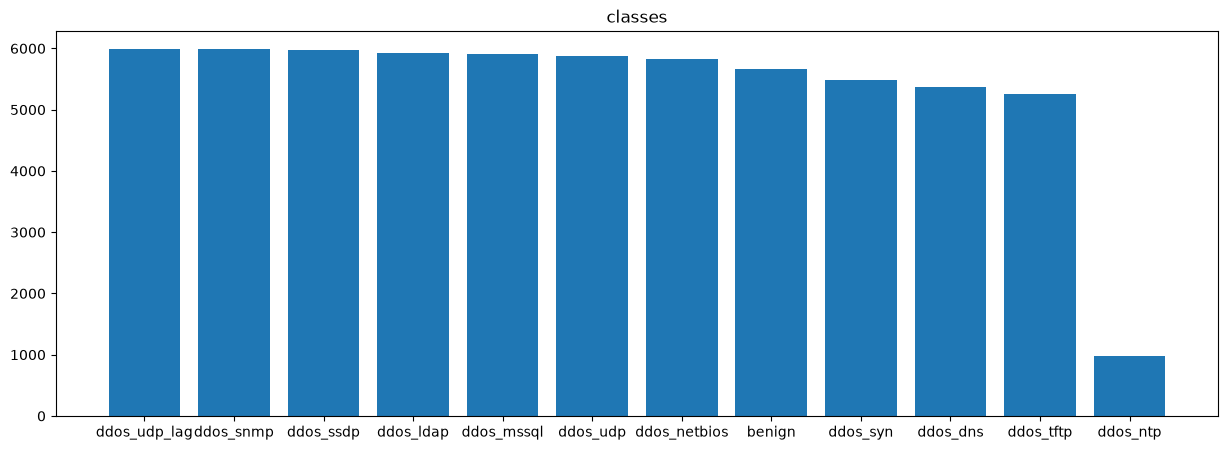

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn as sk
import seaborn as sns

df = pd.read_csv('../dataset.csv', low_memory=False)


classes = df['label'].value_counts().reset_index()
print(classes)

plt.figure(figsize=(15,5))
plt.bar(classes['label'],classes['count'])
plt.title('classes')
plt.show()

In [20]:
n_righe_duplicate = df.duplicated().sum()
print(n_righe_duplicate)

0


# Drop string features

In [ ]:


df_numerical = df.copy()
df_numerical = df.select_dtypes(exclude=['object', 'string'])

print(df_numerical)

       Unnamed: 0   Source Port   Destination Port   Protocol   Flow Duration  \
0               0           634              60495         17           28415   
1               1           634              60495         17               2   
2               2           634              46391         17           48549   
3               3           634              11894         17           48337   
4               4           634              27878         17           32026   
...           ...           ...                ...        ...             ...   
64234       65995         38625              63051         17               1   
64235       65996         58632              18963         17          212238   
64236       65997         46104              64704         17               1   
64237       65998         60686              10440         17          108952   
64238       65999         45602               1387         17               1   

        Total Fwd Packets  

# Compute the variance, if it is 0 we can remove the feature

In [19]:
df_var = df_numerical.var()
zero = df_var[df_var == 0].index.to_list()
print(f"Feature con 0 varianza: {zero}")
df_puro = df_numerical.drop(columns=zero)
df_puro = df_puro.drop(columns=['Unnamed: 0'])
print(df_puro)

Feature con 0 varianza: [' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', 'FIN Flag Count', ' PSH Flag Count', ' ECE Flag Count', 'Fwd Avg Bytes/Bulk', ' Fwd Avg Packets/Bulk', ' Fwd Avg Bulk Rate', ' Bwd Avg Bytes/Bulk', ' Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
        Source Port   Destination Port   Protocol   Flow Duration  \
0               634              60495         17           28415   
1               634              60495         17               2   
2               634              46391         17           48549   
3               634              11894         17           48337   
4               634              27878         17           32026   
...             ...                ...        ...             ...   
64234         38625              63051         17               1   
64235         58632              18963         17          212238   
64236         46104              64704         17               1   
64237         60686              1044

# Can I use Pearson??

1. Is it linear or gaussian?
2. Is it symmetric? (skew)

In [ ]:
#Outliers check
outliers_list = []
for col in df_puro.columns:
    serie = df_puro[col].dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)

    iqr = q3 - q1

    limite_inferiore = q1 - 1.5 * iqr
    limite_superiore = q3 + 1.5 * iqr

    out_cond = (serie < limite_inferiore) | (serie > limite_superiore)
    n_outliers = out_cond.sum()
    pct = (n_outliers/ len(serie)) * 100

    outliers_list.append({
            'feature': col,
            'n_outliers': int(n_outliers),
            'pct_outliers': round(pct, 2),
            'limite_min': round(limite_inferiore, 2),
            'limite_max': round(limite_superiore, 2)
        })

df_outliers = pd.DataFrame(outliers_list).sort_values(by='pct_outliers', ascending=False)

print(df_outliers.head(15))

#Parecchi Outliers e nel nostro caso ci servono per esaminare il traffico di rete anomalo

                   feature  n_outliers  pct_outliers  limite_min  limite_max
58        act_data_pkt_fwd       25561         39.79        1.00        1.00
52     Subflow Fwd Packets       17738         27.61        2.00        2.00
4        Total Fwd Packets       17738         27.61        2.00        2.00
24             Fwd IAT Std       15644         24.35        0.00        0.00
22           Fwd IAT Total       15556         24.22      -74.00      126.00
25             Fwd IAT Max       15550         24.21      -74.00      126.00
2                 Protocol       15369         23.92       17.00       17.00
56  Init_Win_bytes_forward       15311         23.83       -1.00       -1.00
20            Flow IAT Max       15114         23.53    -4886.00     8146.00
19            Flow IAT Std       15006         23.36     -378.96      631.59
18           Flow IAT Mean       14960         23.29     -297.57      498.62
23            Fwd IAT Mean       14648         22.80      -74.00      126.00

In [ ]:
df_skew = df_puro.skew()

perc = (df_skew.abs() > 1).mean() * 100
print(perc) #Percentuale di features asimmetriche => non gaussiane perchè per definizione la gaussiana è simmetrica

# Troppi outliers e molta asimmetria quindi pearson non si può usare => useremo spearman

84.05797101449275


# Check for duplicate features (corr ~ 1)

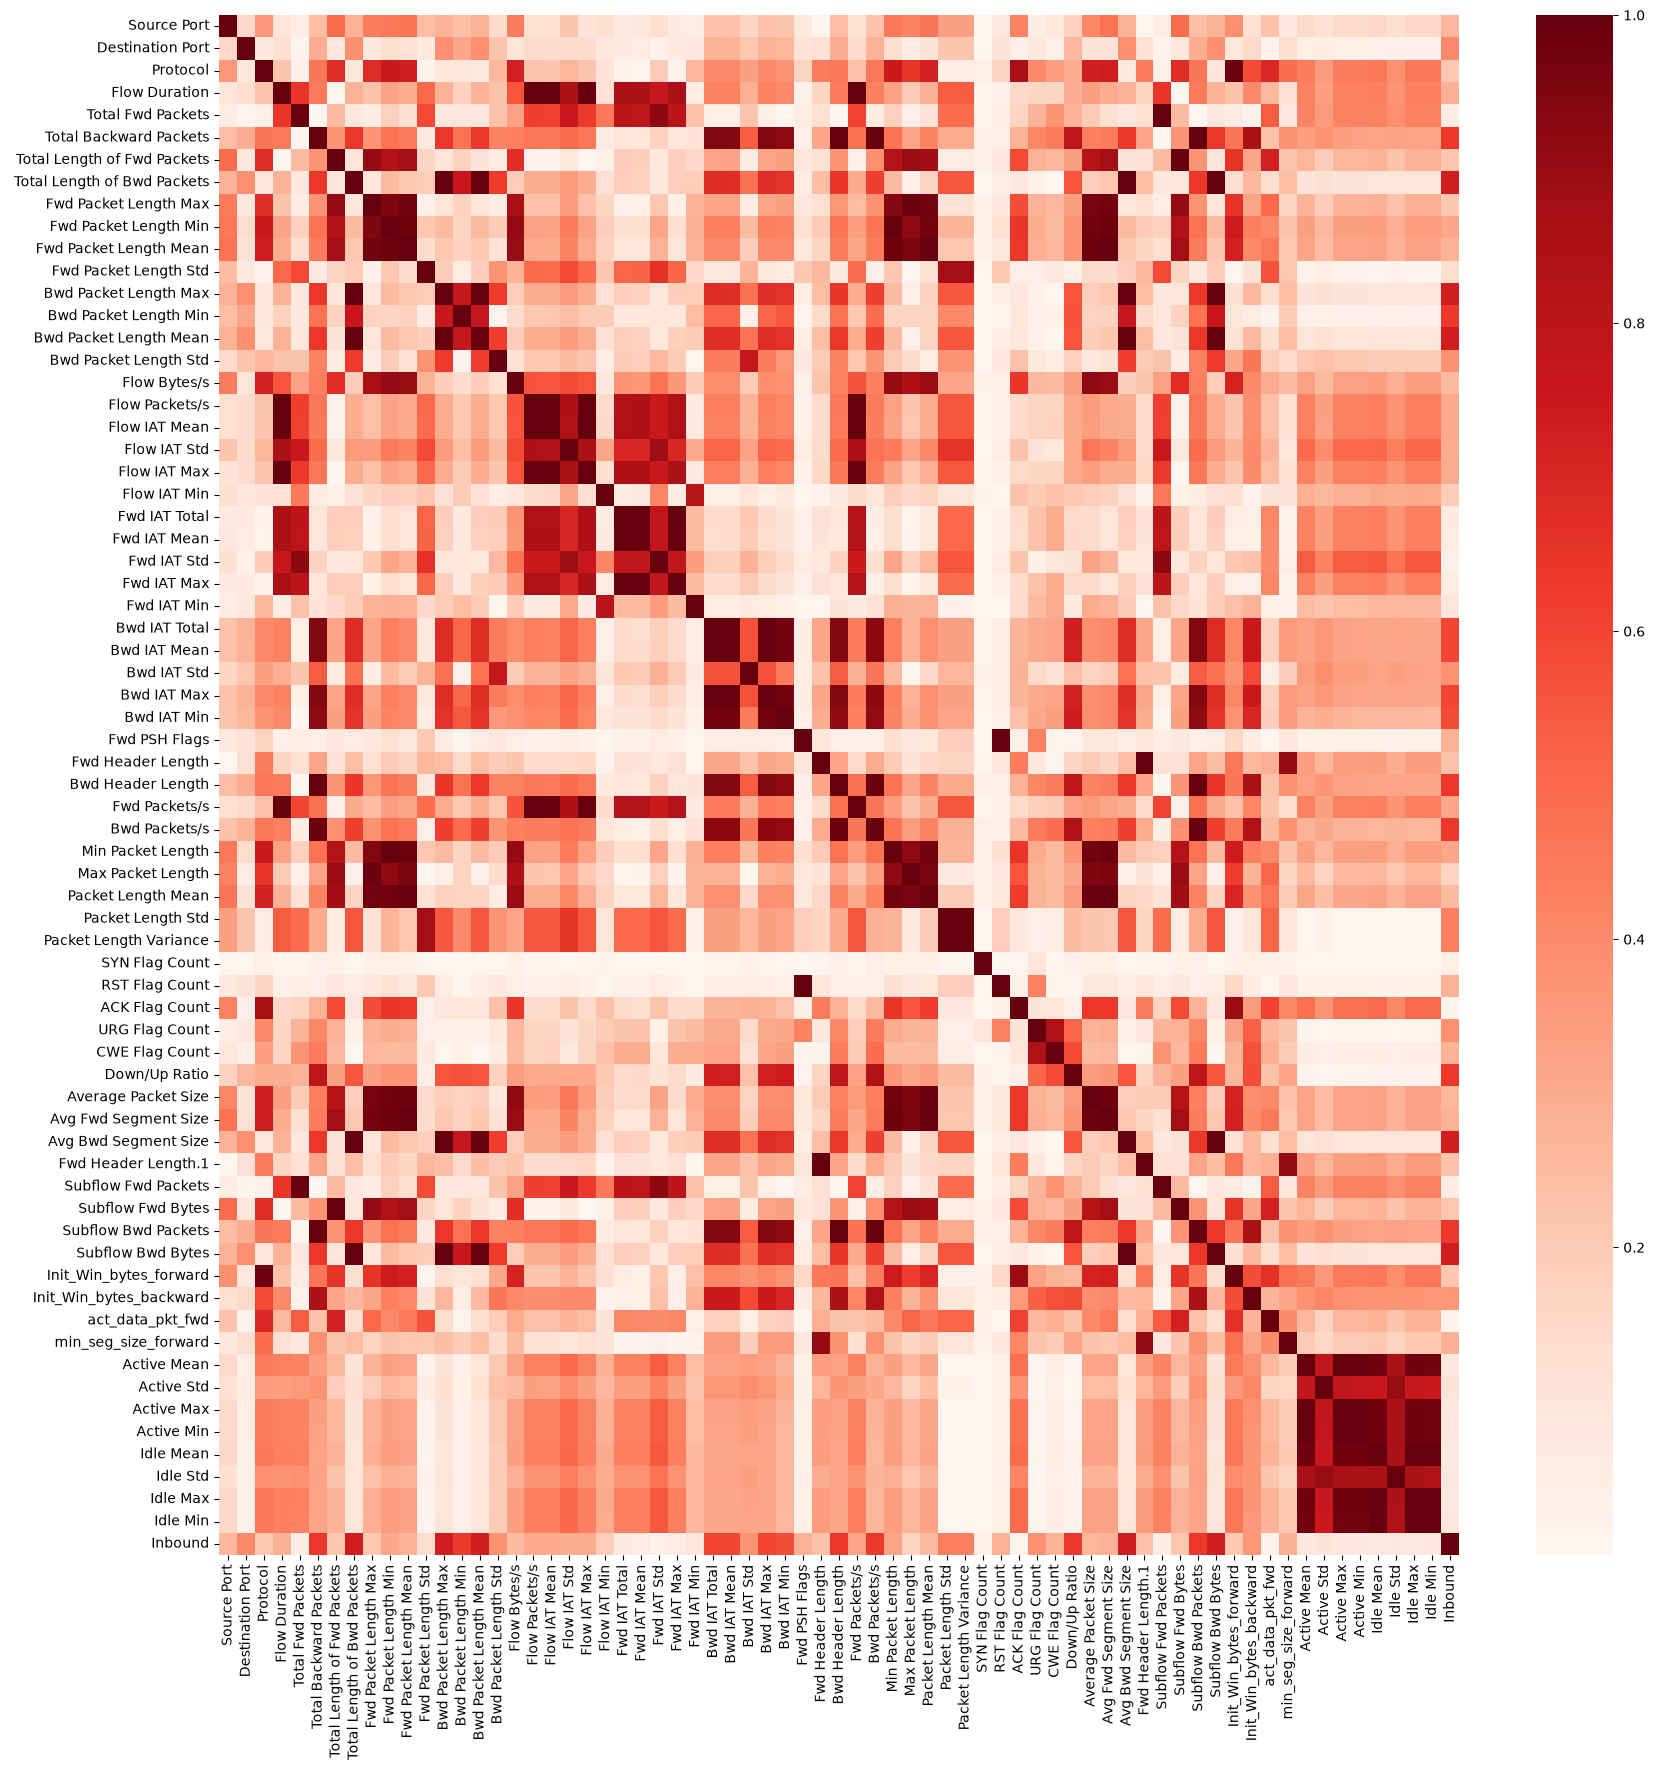

In [64]:
corr_matrix = df_puro.corr(method="spearman").abs()

plt.figure(figsize=(20,20))
sns.heatmap(corr_matrix, cmap="Reds")
plt.show()


# We can remove some features, in particular, we fix a threshold, for example corr = 0.95 because we can remove one of two features that are strictly correlated so they present the same information. We make a choice based on the noise and other informations.

In [71]:
mask = np.triu(np.ones(corr_matrix.shape, dtype=bool),k=1)

tri_upper_corr = corr_matrix.where(mask)
righe_idx, col_idx = np.where(tri_upper_corr > 0.85)

for r, c in zip(righe_idx, col_idx):
  feat_1 = tri_upper_corr.index[r]
  feat_2 = tri_upper_corr.columns[c]
  valore = tri_upper_corr.iloc[r, c]
  

colonne_da_scartare = [
    tri_upper_corr.columns[c] for c in np.unique(col_idx)
] 
print(f"\nTotale colonne da droppare: {len(colonne_da_scartare)}")
print(colonne_da_scartare)

df_ridotto = df_puro.drop(columns=colonne_da_scartare)
print(df_ridotto.shape)




Totale colonne da droppare: 44
[' Fwd Packet Length Max', ' Fwd Packet Length Min', ' Fwd Packet Length Mean', 'Bwd Packet Length Max', ' Bwd Packet Length Mean', 'Flow Bytes/s', ' Flow Packets/s', ' Flow IAT Mean', ' Flow IAT Max', 'Fwd IAT Total', ' Fwd IAT Mean', ' Fwd IAT Std', ' Fwd IAT Max', 'Bwd IAT Total', ' Bwd IAT Mean', ' Bwd IAT Max', ' Bwd IAT Min', ' Bwd Header Length', 'Fwd Packets/s', ' Bwd Packets/s', ' Min Packet Length', ' Max Packet Length', ' Packet Length Mean', ' Packet Length Std', ' Packet Length Variance', ' RST Flag Count', ' ACK Flag Count', ' Average Packet Size', ' Avg Fwd Segment Size', ' Avg Bwd Segment Size', ' Fwd Header Length.1', 'Subflow Fwd Packets', ' Subflow Fwd Bytes', ' Subflow Bwd Packets', ' Subflow Bwd Bytes', 'Init_Win_bytes_forward', ' Init_Win_bytes_backward', ' min_seg_size_forward', ' Active Max', ' Active Min', 'Idle Mean', ' Idle Std', ' Idle Max', ' Idle Min']
(64239, 25)


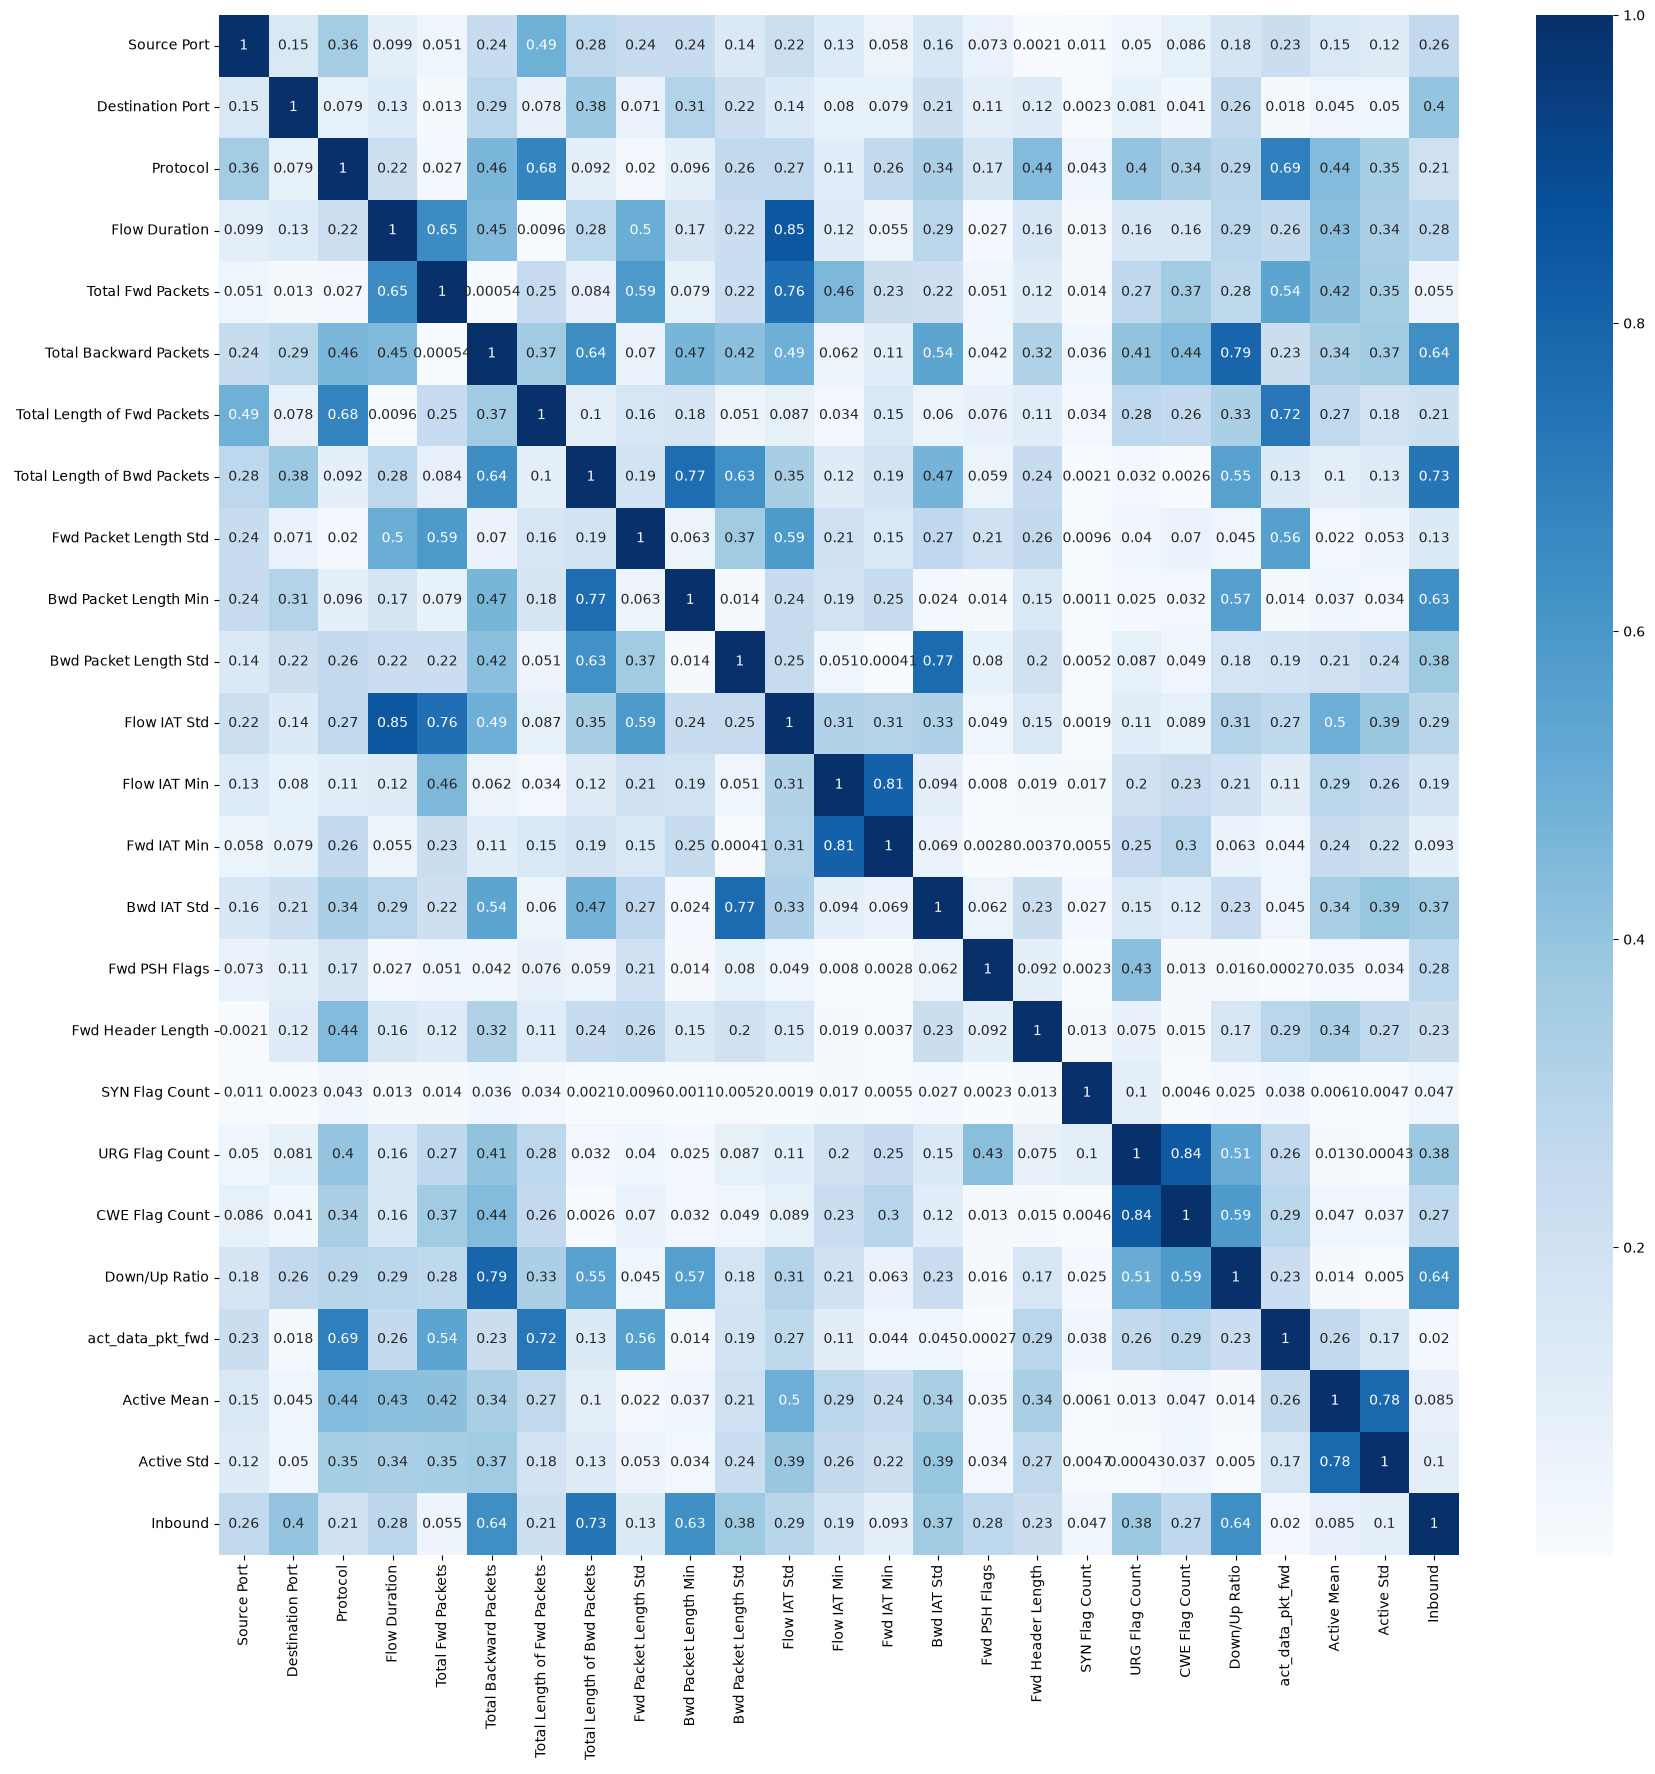

In [72]:
#Recompute the correlation matrix

corr_matrix_reducted = df_ridotto.corr(method="spearman").abs()

plt.figure(figsize=(20,20))
sns.heatmap(corr_matrix_reducted, cmap="Blues", annot=True)
plt.show()